### TEL354 - Minería de datos
# Clase 10: Generative Classifiers
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase10 import *

# Modelos generativos

Modelan la distribución conjunta de las características de entrada y las clases de salida. Es decir, aprenden cómo se generan los datos observados a partir de cada clase.

Ejemplos de modelos generativos: Naive Bayes, Modelos Gráficos Probabilísticos (PGM), y Redes Generativas Adversarias (GAN).

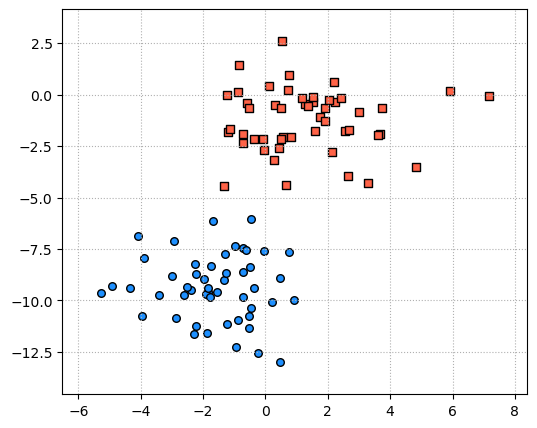

In [2]:
generative()

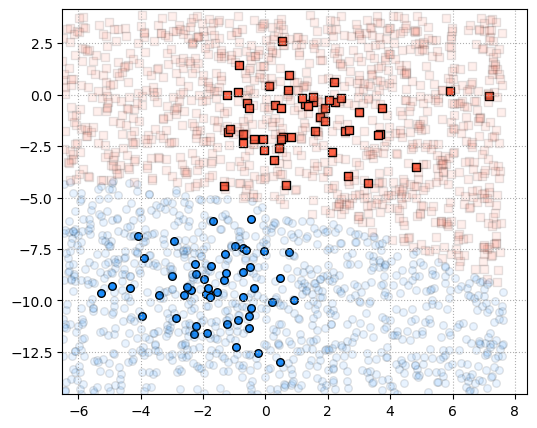

In [3]:
generative(new_data=True)

# First Generative Model

Los siguientes datos han sido generados por medio de una distribución uniforme.

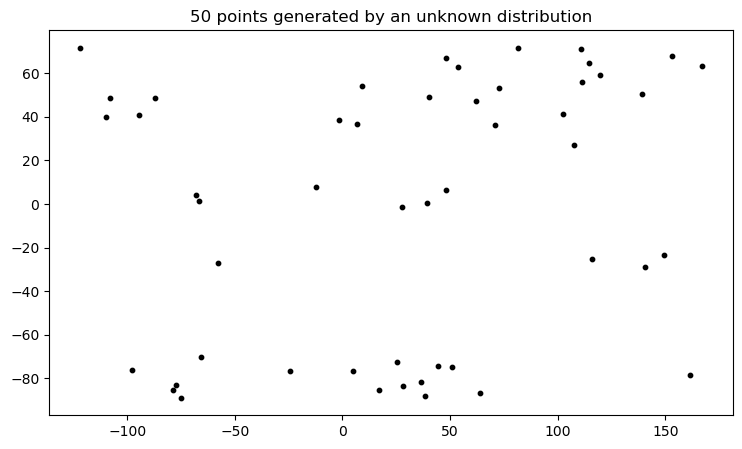

In [4]:
first_generative_model(num_points=50, true_distribution=False, new_points=None)

# Modelos probabilísticos

Estos modelos asignan probabilidades a diferentes eventos o resultados posibles, lo que permite cuantificar la incertidumbre y hacer predicciones o tomar decisiones basadas en esta información probabilística.

Por ejemplo, Gaussian Naive Bayes es un modelo probabilístico que se utiliza comúnmente en problemas de clasificación en aprendizaje automático.

## Espacio Muestral (Sample Space)

Conjunto completo de todos los valores que puede tomar una observación $𝐱$. 

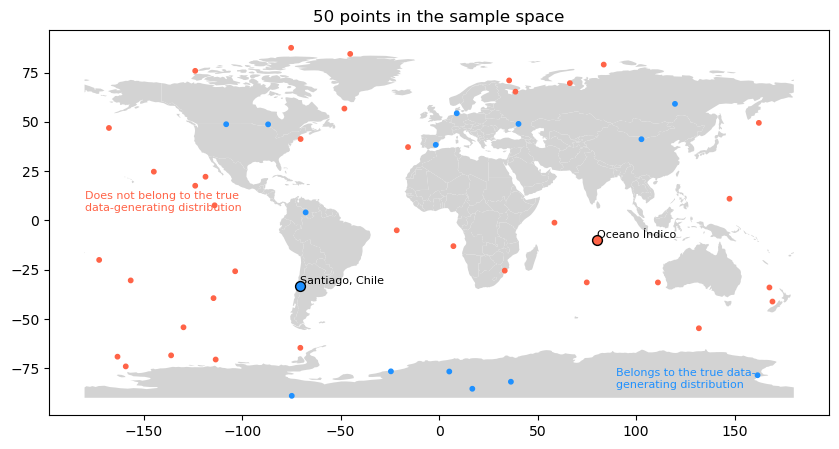

In [5]:
coords = [(-33.45694, -70.64827), (-10, 80)]
labels = ['Santiago, Chile', 'Oceano Índico']
first_generative_model(num_points=50, true_distribution=True, sample_space=True, new_points=coords, points_labels=labels)

## Función de Densidad de Probabilidad (Probability Density Function)

Función que mapea un punto $𝐱$ en el espacio muestral a un número entre 0 y 1. 

En el ejemplo del mapa mundial, la función de densidad de probabilidad (PDF) sería cero en todos los puntos del mar y constante en todos los puntos de la masa terrestre.

# Gaussian Naive Bayes

Se basa en el teorema de Bayes y asume que las características son independientes entre sí, dadas las clases objetivo. Utiliza distribuciones Gaussianas para modelar la probabilidad condicional de las características dado un valor de clase. Por lo tanto, asigna probabilidades a las clases objetivo basadas en las observaciones de las características. Es un modelo simple y rápido porque se ajusta simplemente encontrando la media y la desviación estándar de los datos en cada clase.

# Teorema de Bayes

Establece la relación entre la probabilidad condicional de un evento A dado un evento B, y la probabilidad condicional de B dado A. Para tareas de clasificación, el teorema de Bayes calcula la probabilidad de que un objeto $x$ pertenezca a una clase $y$, dado: 

$$ P(y|X) = \frac{P(X|y) \cdot P(y)}{P(X)} $$

$P(y|X)$ es la probabilidad de que ocurra la clase $y$ dado que los valores de los atributos predictivos son $X$, $P(X|y)$ es la probabilidad de que ocurran los atributos predictivos con valores $X$ dado que la clase es $y$, $P(y)$ es la probabilidad a priori de la clase $y$, y $P(X)$ es la evidencia que tenemos.


### Ejemplo: Teorema de bayes para calcular la probabilidad de COVID-19


In [6]:
display(interactive_plot)

interactive(children=(FloatSlider(value=0.05, description='Prob. COVID-19:', layout=Layout(width='400px'), max…

# Naive Bayes classifier (Clasificador bayesiano ingenuo)

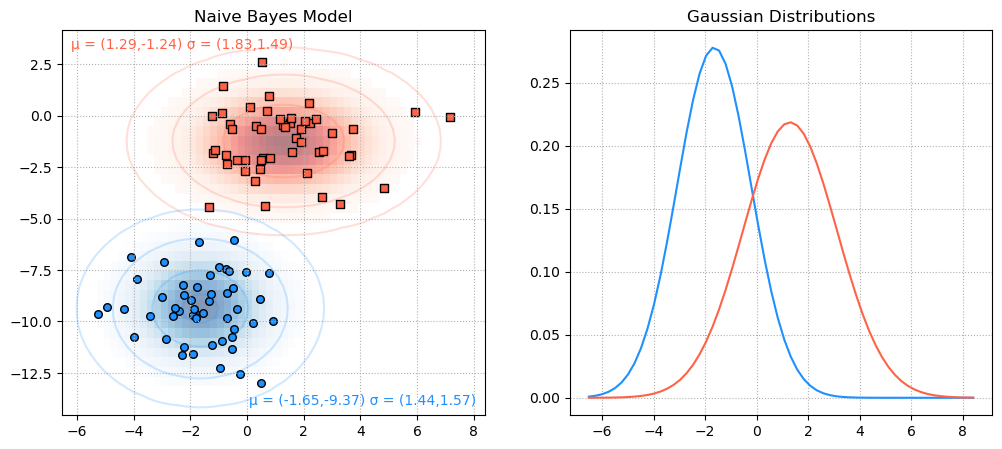

In [7]:
X_test=(4, -6)
generative(distribution=True, Xnew=None)

### Ejemplo: Identificando la tasa de admitidos en UCBerkeley

In [8]:
df = pd.read_csv("ucbadmissions.csv")
df.head()

,Admit,Gender,Dept,Freq
0,Admitted,Male,A,512
1,Rejected,Male,A,313
2,Admitted,Female,A,89
3,Rejected,Female,A,19
4,Admitted,Male,B,353


In [9]:
df_deagg = deaggregate_statistics(df)
df_deagg

,Admit,Gender,Dept
0,Admitted,Male,A
1,Admitted,Male,A
2,Admitted,Male,A
3,Admitted,Male,A
4,Admitted,Male,A
...,...,...,...
4521,Rejected,Female,F
4522,Rejected,Female,F
4523,Rejected,Female,F
4524,Rejected,Female,F


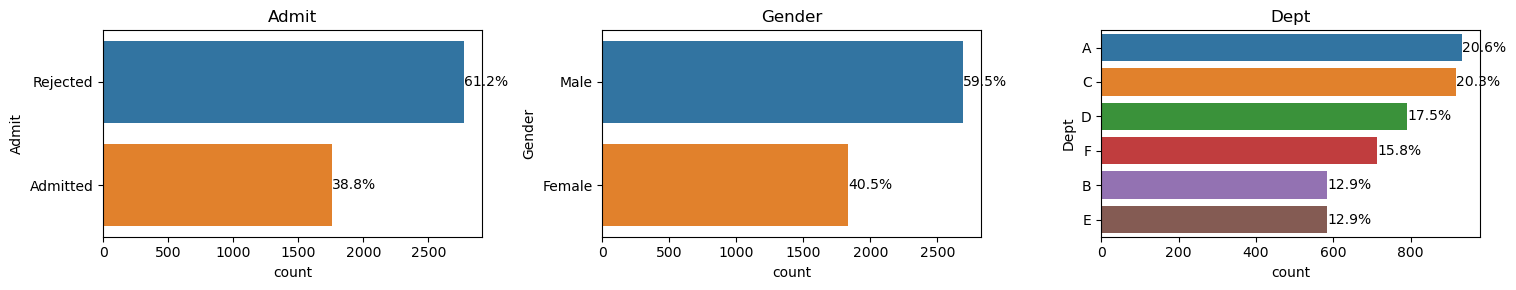

In [10]:
plot_statistics(df_deagg)

In [11]:
lbl = LabelEncoder()

df_deagg['Gender'] = lbl.fit_transform(df_deagg['Gender'])
df_deagg['Admit'] = lbl.fit_transform(df_deagg['Admit'])
df_deagg = pd.concat([df_deagg, pd.get_dummies(df_deagg['Dept'], prefix='dept')], axis=1).drop(columns='Dept')

In [12]:
df_deagg

,Admit,Gender,dept_A,dept_B,dept_C,dept_D,dept_E,dept_F
0,0,1,1,0,0,0,0,0
1,0,1,1,0,0,0,0,0
2,0,1,1,0,0,0,0,0
3,0,1,1,0,0,0,0,0
4,0,1,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...
4521,1,0,0,0,0,0,0,1
4522,1,0,0,0,0,0,0,1
4523,1,0,0,0,0,0,0,1
4524,1,0,0,0,0,0,0,1


In [13]:
X_train_mat, X_test_mat, y_train_vec, y_test_vec = train_test_split(df_deagg.loc[:, 'Gender':'dept_F'], 
                                                                    df_deagg['Admit'], 
                                                                    test_size=.30, random_state=11238)

In [14]:
nb_classifier = GaussianNB().fit(X_train_mat, y_train_vec)

In [15]:
y_hat = nb_classifier.predict(X_test_mat)

cnf = confusion_matrix(y_test_vec, y_hat)/len(y_test_vec)

target_label = ['Admitted', 'Rejected']

# Matriz de confusión

El modelo clasifica de forma correcta aproximadamente el 70% de los casos como positivos o negativos, y tiende a desempeñarse de peor manera para predicir los casos aceptados.

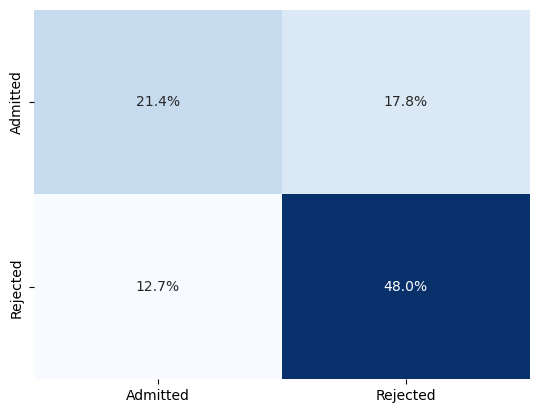

In [16]:
sns.heatmap(cnf, xticklabels=target_label, yticklabels=target_label, annot=True, fmt=".1%", cbar=False, cmap='Blues')
plt.show()

# Classification report

In [17]:
print(classification_report(y_test_vec, y_hat))

              precision    recall  f1-score   support

           0       0.63      0.55      0.58       533
           1       0.73      0.79      0.76       825

    accuracy                           0.69      1358
   macro avg       0.68      0.67      0.67      1358
weighted avg       0.69      0.69      0.69      1358



# Curva ROC

Representa la tasa de verdaderos positivos frente a la tasa de falsos positivos para diferentes umbrales de decisión. Cuanto más cerca esté el área bajo la curva (AUC) de 1, mejor será el rendimiento del modelo, ya que indica una mayor capacidad de distinguir entre las clases positivas y negativas. Un AUC de 0.5 indica un rendimiento aleatorio, mientras que un AUC de 1 indica un rendimiento perfecto.

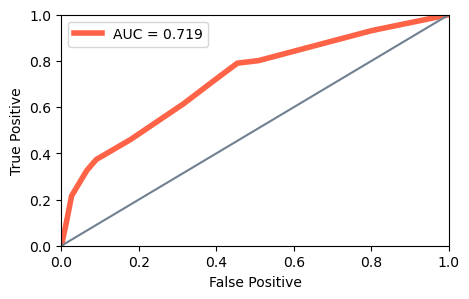

In [18]:
plot_roc_auc(nb_classifier, X_test_mat, y_test_vec)

### Efecto de la probabilidad a priori en el modelo

Un aspecto a considerar en el algoritmo NB (y de manera más general en el marco analítico Bayesiano), es la ventaja de poder ingresar información previa sobre cómo se comportan nuestras clases. Esta información conocida como probabilidad a priori, interactúa con la verosimilitud del evento para actualizarlo en función del comportamiento pasado.

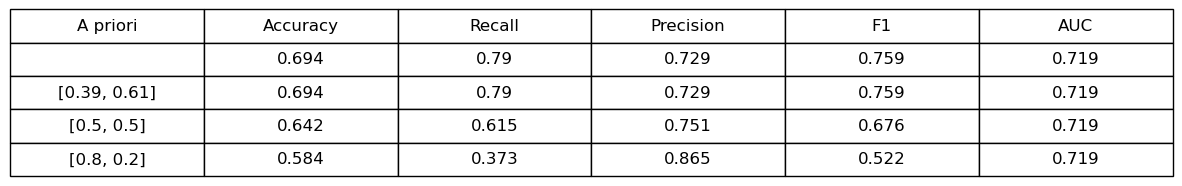

In [19]:
priors_list = [None, [0.39, 0.61], [0.5, 0.5], [0.8, 0.2]]
compare_priors(X_train_mat, X_test_mat, y_train_vec, y_test_vec, priors_list)